<a href="https://colab.research.google.com/github/alwinbshaji/Data-Science/blob/main/machinelearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

machine learning

In [ ]:
#multivariate linear regressiom
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
mydf = pd.read_csv('/content/drive/MyDrive/faith fahhhhh/auto-mpg.csv')
mydf.head(2)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320


In [ ]:
#data cleaning
#for some rows the horsepower value '?' we have to remove these rows
mydf[mydf['horsepower']=='?'] #we hab=ve accourances of hp as ?inorsd==der
#inorder to remove those rows ar first collect the indexes of thoe rows
hp_qm_indexs = mydf[mydf['horsepower']=='?'].index

#now usein gthese indexes remove those rows of data
mydf.drop(hp_qm_indexs,inplace=True) #inplcae--change the original dataframe


In [ ]:
mydf[mydf['horsepower']=='?'] #now there are no rows with hp as ?
mydf['horsepower']= mydf['horsepower'].astype(float)

In [ ]:
mydf.info() #the hourse power os string we have to convert it to a float

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    int64  
 7   origin        392 non-null    int64  
 8   car name      392 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 30.6+ KB


In [ ]:
mydf

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,1,ford ranger


In [ ]:
#split the dataset for input and output
x= mydf.iloc[:,1:6]

#our input columns cylinders , dispalcemnet, horsepower, weight , acc
y= mydf.iloc[:,0] #allrows 0 index xol

In [ ]:
x.shape

(392, 5)

In [ ]:
from sklearn import linear_model
#create multi variate linear regrasiion model
from sklearn.linear_model import LinearRegression

mymodel = LinearRegression()
mymodel.fit(x,y)

LinearRegression()

In [ ]:
#ewe will try to make a prediction
input_data = np.array([8,220,195,3042,6.7])
input_data
#convert the data into 2D
input_data = input_data.reshape((-1,5))
input_data

#making the prediction
print("mpg:",mymodel.predict(input_data)[0])

mpg: 18.263857568586783


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# classification algorithms

In [ ]:
# logistic regression
mydf= pd.read_csv('/content/drive/MyDrive/faith fahhhhh/heights_weights.csv')
mydf

,Height,Weight,Male
0,73.847017,241.893563,1
1,68.781904,162.310473,1
2,74.110105,212.740856,1
3,71.730978,220.042470,1
4,69.881796,206.349801,1
...,...,...,...
9995,66.172652,136.777454,0
9996,67.067155,170.867906,0
9997,63.867992,128.475319,0
9998,69.034243,163.852461,0


In [ ]:
import seaborn as sns
sns.set() #import and initialize the seaborn library

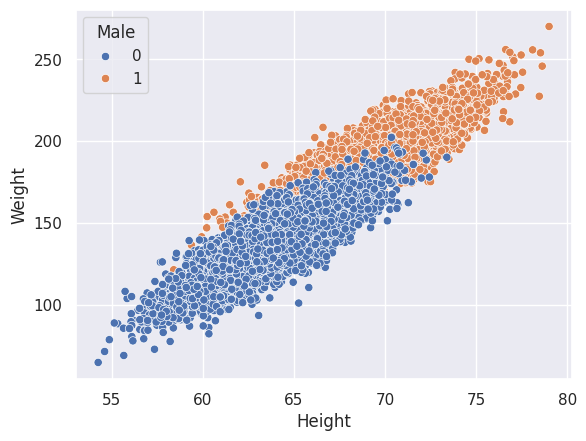

In [ ]:
myplot = sns.scatterplot(x="Height",y="Weight",data=mydf,hue="Male")

In [ ]:
#split the data as input and output
x= mydf.iloc[:,0:2].values #all rows cols from 0 to 2-1
y= mydf.iloc[:,2].values #all rows 2nd index col

In [ ]:
#split the data into training and testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

mymodel= linear_model.LogisticRegression()
mymodel=mymodel.fit(x_train,y_train) #fit the train the model

In [ ]:
Height = 61
Weight = 125

prediction = mymodel.predict([(Height,Weight)])
print(prediction[0])

if prediction[0]==1:
  result = "Male"
else:
  result = "Female"

print(result)

0
Female


In [ ]:
#since its classification alsgot=rith
#we will be finding the binaryy cross entropy (BCe)
#as part of the evaluation

from sklearn.metrics import log_loss

In [ ]:
#using the x_test , btain the predictions by our model
testing_output  = mymodel.predict_proba(x_test)
testing_output
#we willl get an array of two columnms
# the probability of gettign the xero class
# the porbability of getting the 1 class

array([[2.30010229e-01, 7.69989771e-01],
       [4.40988617e-03, 9.95590114e-01],
       [1.51255314e-01, 8.48744686e-01],
       ...,
       [9.93510848e-01, 6.48915213e-03],
       [8.35130772e-03, 9.91648692e-01],
       [9.99574556e-01, 4.25443651e-04]], shape=(2000, 2))

In [ ]:
#the binary cross entrroppy loss expextrs the probability values
# of the class 1 (positive class). so split our teesting_output
#to obtain only the second column
testing_output = testing_output[:,1] #all rows , 1st indx clo


In [ ]:
#now we can compare the testing outvs the actual y test to calcuate
#the bce loss
bceloss= log_loss(y_test,testing_output)
print("BCE ISL",bceloss)
# if bce is 0 the its a perfect model
#0.i to 0.3 its a good model
# 0.3-.6 avg
# > 0.7 not good model
#0.1 - 0.3


BCE ISL 0.19593092363438083
